# Gate Planner: road times and the walk through the terminal

**The question the planner answers:** "I'm flying out of Hong Kong. When should I leave for the airport?"

**How it answers:**

```
door to gate = road + check-in and bag drop + immigration and security + walk to the gate
deadline     = bag drop closes (departure − 60 min) with bags, otherwise gate closes (departure − 15 min)
leave by     = deadline − door to gate, taken at a cautious percentile (85th by default)
```

Each of the four legs is a range, not a single number. The planner draws 2,000 possible journeys, adds the legs
up, and picks a leave-by time that would have been early enough in 85 of 100 of them.

This notebook shows the data behind each leg and one worked example. Nothing here calls an outside service: the
Google answers were fetched once and are read from `data/raw/google/`.

**Key findings**

- **Road times are real and vary by hour.** From five starting points the typical drive to Terminal 1 is 29 to 42
  minutes. Bad traffic adds up to 26 minutes, mostly in the evening rush (Causeway Bay at 18:00: 59 minutes
  against 33 at its best).
- **A worked example.** For CX135 at 19:00 from Central with one bag, door to gate usually takes 72 minutes and up
  to 91. Bag drop closes at 18:00, so the plan says leave by 16:35.
- **Choices move the plan.** Checking in online with no bags moves the leave-by time to 17:40, more than an hour
  later. A visitor without e-Channel should leave 5 minutes earlier.
- **Gates are published about 2.5 hours before departure** (24 real Cathay departures). Until then the planner
  assumes a far gate; when gate 49 was published, the plan moved 5 minutes later.
- **Real gate numbers fit the terminal model.** 99.8% of 15,572 Cathay departures and every arrival map to a
  zone. About two thirds use the three western zones, where walks are longest.


**What is real and what is assumed**

| Leg | Source | Label |
|---|---|---|
| Road | Google Routes traffic model, per starting point and hour | REAL (Google's model) |
| Flight time, delay, gate, and when the gate was published | HKIA past flights and OAG status history | REAL |
| Check-in queue, immigration and security times | Our assumptions in `config/engine.yaml` | ASSUMED |
| Terminal zones and walking distances | Our reading of the public terminal map, `data/reference/hkg_zones.yaml` | ASSUMED |
| Airport Express | Timetable: 24 min ride, a train every 10 min | ASSUMED |

In [1]:
import os
os.environ["OFFLINE"] = "1"   # nothing in this notebook calls an outside service

from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flowcore.engine.gate_planner import PlanRequest, airport_express, plan, road_samples
from flowcore.engine.time_to_gate import TransferInputs, draw_transfer, load_config, rng_for
from flowcore.engine.zones import load_zones
from flowcore.parse.hkia import HKT
from flowcore.scenario import load_scenario
from flowresearch import charts, eda

charts.use_style()
pd.set_option("display.width", 160)
config, zones = load_config(), load_zones()
flights = load_scenario("2026-10-22-evening")["flights"]
at = lambda hour, minute=0: datetime(2026, 10, 22, hour, minute, tzinfo=HKT)

## 1. The road: what we ask Google

For each starting point and each hour, the planner sends Google Routes two requests for a drive to
"Hong Kong International Airport Terminal 1":

- **`BEST_GUESS`**: Google's expected drive time with traffic. We use it as the typical time.
- **`PESSIMISTIC`**: Google's bad-traffic time. We use it as the upper end.

Each reply also carries the drive time with no traffic (`staticDuration`) and the distance.

Two details matter:

- **Google only predicts traffic for the future.** The demo replays Thursday 22 October 2026, so the planner asks
  about the same weekday and hour on a fixed future Thursday (19 November 2026).
- **Answers are cached.** 5 starting points × 11 hours (11:00 to 21:00) × 2 traffic models = 110 calls, made once.
  After that the planner works offline, and if Google is ever unavailable it falls back to the Airport Express
  timetable and says so.

In [2]:
roads = eda.google_roads()
print(f"{len(roads)} origin-hour rows from {2 * len(roads)} cached Google replies, for {roads['when'].dt.date.iloc[0]:%A %d %B %Y}")
roads.pivot(index="origin", columns="hour", values="typical").round(0).astype(int).rename_axis(columns="typical minutes, leaving at hour")

55 origin-hour rows from 110 cached Google replies, for Thursday 19 November 2026


"typical minutes, leaving at hour",11,12,13,14,15,16,17,18,19,20,21
origin,,,,,,,,,,,
Causeway Bay,34,34,34,34,34,36,38,42,40,34,33
Central,32,32,32,32,32,33,35,38,37,32,30
Sha Tin,34,33,33,34,33,33,33,34,33,33,32
Tseung Kwan O,36,35,35,35,35,35,37,42,38,35,34
Tsim Sha Tsui,29,30,29,29,30,30,30,32,34,29,29


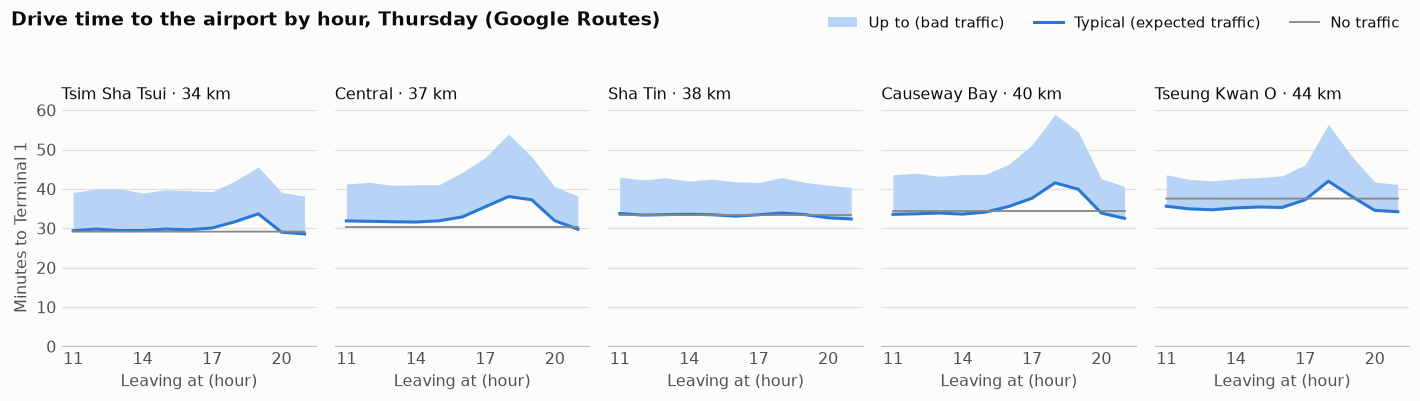

In [3]:
order = roads.groupby("origin")["typical"].mean().sort_values().index
fig, axes = plt.subplots(1, len(order), figsize=(13, 3.4), sharey=True)
for ax, origin in zip(axes, order):
    one = roads[roads["origin"] == origin]
    ax.fill_between(one["hour"], one["typical"], one["upper"], color=charts.LIGHT_BLUE, linewidth=0, label="Up to (bad traffic)")
    ax.plot(one["hour"], one["typical"], color=charts.BLUE, label="Typical (expected traffic)")
    ax.plot(one["hour"], one["free_flow"], color=charts.GREY, linewidth=1.2, label="No traffic")
    ax.set_title(f"{origin} · {one['km'].iloc[0]:.0f} km", loc="left", fontsize=10.5, color=charts.INK)
    ax.set_xticks([11, 14, 17, 20]); ax.set_xlabel("Leaving at (hour)")
axes[0].set_ylabel("Minutes to Terminal 1"); axes[0].set_ylim(0, None)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=3, bbox_to_anchor=(0.99, 1.08))
fig.suptitle("Drive time to the airport by hour, Thursday (Google Routes)", x=0.01, ha="left", y=1.06,
             fontsize=12.5, fontweight="bold")
plt.tight_layout(); plt.show()

In [4]:
summary = roads.groupby("origin").agg(
    km=("km", "first"), no_traffic=("free_flow", "first"),
    typical_best=("typical", "min"), typical_worst=("typical", "max"), bad_traffic_worst=("upper", "max"))
summary["worst_hour"] = roads.loc[roads.groupby("origin")["upper"].idxmax()].set_index("origin")["hour"]
summary["bad_traffic_adds_min"] = summary["bad_traffic_worst"] - summary["typical_best"]
summary.loc[order].round(0).astype(int)

,km,no_traffic,typical_best,typical_worst,bad_traffic_worst,worst_hour,bad_traffic_adds_min
origin,,,,,,,
Tsim Sha Tsui,34,29,29,34,46,19,17
Central,37,30,30,38,54,18,24
Sha Tin,38,33,32,34,43,11,11
Causeway Bay,40,34,33,42,59,18,26
Tseung Kwan O,44,38,34,42,56,18,22


**How to read it.** The dark line is what the drive usually takes. The band above it is how much worse it gets in
bad traffic. The band is widest in the evening rush, which is exactly when the scenario's flights leave. A planner
that used one fixed drive time would be right at lunchtime and wrong at 18:00.

## 2. From two numbers to a range of drives

Google gives two numbers per hour. The planner turns them into a range: the typical time is the middle (half of
drives are faster), and the bad-traffic time is the 95th percentile (1 drive in 20 is slower). A drive is never
taken to be faster than 60% of the typical time.

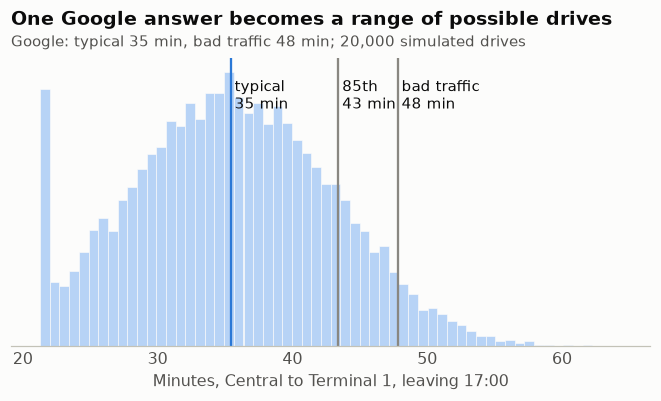

In [5]:
road = eda.road_lookup(roads, "Central")(at(17))
drives = road_samples(road, config, rng_for(config["seed"], "notebook-road"), 20000)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(drives, bins=60, color=charts.LIGHT_BLUE, edgecolor=charts.SURFACE, linewidth=0.4)
for percentile, name in [(50, "typical"), (85, "85th"), (95, "bad traffic")]:
    value = np.percentile(drives, percentile)
    ax.axvline(value, color=charts.BLUE if percentile == 50 else charts.GREY, linewidth=1.5)
    ax.text(value + 0.3, ax.get_ylim()[1] * 0.93, f"{name}\n{value:.0f} min", fontsize=9.5, color=charts.INK, va="top")
ax.set_xlabel("Minutes, Central to Terminal 1, leaving 17:00"); ax.set_yticks([])
charts.title(ax, "One Google answer becomes a range of possible drives",
             f"Google: typical {road.typical:.0f} min, bad traffic {road.upper:.0f} min; 20,000 simulated drives")
plt.show()

## 3. Inside the terminal: zones and walking distances

Terminal 1 is modelled as one long spine, from the East Hall to the West Hall, with branches off it. Every gate
and aircraft stand number belongs to a zone. The walk between two zones is:

```
walk (metres) = distance along the spine + the two branches + 150 m to pass through security
                (120 m if both ends are in the same zone)
minutes       = metres ÷ walking speed (1.2 m/s on average, varied per person), plus the train for Midfield
```

The gate and stand numbers are real (HKIA). The zones and distances are our reading of the public terminal map,
not a survey. With Cathay's or the airport's measured walking times, this table is the one thing to replace.

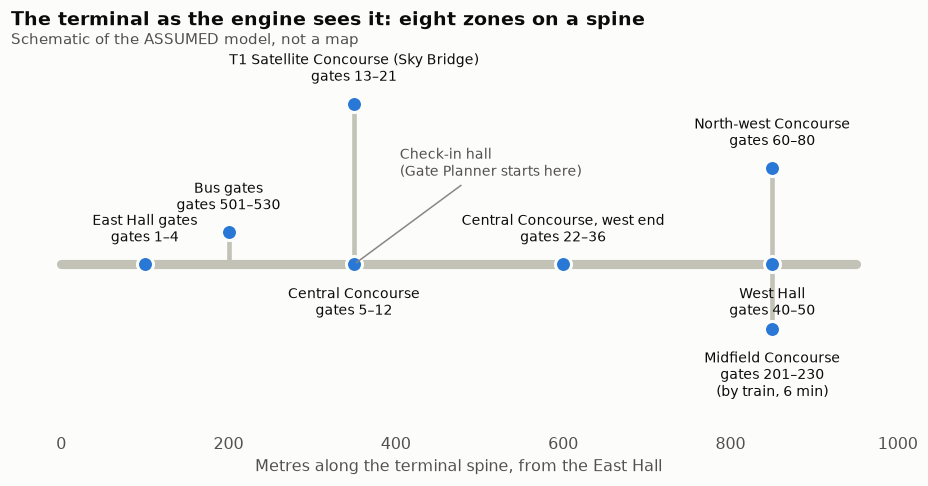

In [6]:
ranges = {}
for low, high, zone in zones.ranges:
    ranges.setdefault(zone, []).append(f"{low}–{high}")
fig, ax = plt.subplots(figsize=(10.5, 4.4))
ax.plot([0, 950], [0, 0], color=charts.AXIS, linewidth=6, solid_capstyle="round", zorder=1)
for key, zone in zones.zones.items():
    by_train = "train_minutes" in zone
    y = -200 if by_train else zone["branch"]
    if zone["branch"] or by_train:
        ax.plot([zone["x"], zone["x"]], [0, y], color=charts.AXIS, linewidth=3, zorder=1)
    ax.scatter(zone["x"], y, s=110, color=charts.BLUE, edgecolor=charts.SURFACE, linewidth=2, zorder=3)
    label = f"{zone['name']}\ngates {', '.join(ranges.get(key, []))}" + ("\n(by train, 6 min)" if by_train else "")
    below = y <= 0 and not by_train and key in ("central", "west")
    ax.annotate(label, (zone["x"], y), xytext=(0, -14 if (below or by_train) else 12), textcoords="offset points",
                ha="center", va="top" if (below or by_train) else "bottom", fontsize=9, color=charts.INK)
ax.annotate("Check-in hall\n(Gate Planner starts here)", (350, 0), xytext=(30, 58), textcoords="offset points",
            fontsize=9, color=charts.SECOND_INK, ha="left", arrowprops={"arrowstyle": "-", "color": charts.GREY})
ax.set_xlim(-60, 1010); ax.set_ylim(-520, 640); ax.grid(False); ax.set_yticks([])
ax.set_xlabel("Metres along the terminal spine, from the East Hall"); ax.spines["bottom"].set_visible(False)
charts.title(ax, "The terminal as the engine sees it: eight zones on a spine", "Schematic of the ASSUMED model, not a map")
plt.show()

In [7]:
start = config["planner"]["start_zone"]
speed = config["walk_speed"]["mean"]
walk = pd.DataFrame([{
    "to": zone["name"], "gates": ", ".join(ranges.get(key, [])),
    "metres": zones.walk_m(start, key),
    "train_min": zones.train_minutes(start, key)} for key, zone in zones.zones.items()])
walk["typical_minutes"] = (walk["metres"] / speed / 60 + walk["train_min"]).round(0).astype(int)
print(f"Walk from the check-in hall ({zones.name(start)}) at {speed} m/s")
walk.sort_values("typical_minutes").reset_index(drop=True)

Walk from the check-in hall (Central Concourse) at 1.2 m/s


,to,gates,metres,train_min,typical_minutes
0,Central Concourse,5–12,120.0,0.0,2
1,East Hall gates,1–4,400.0,0.0,6
2,"Central Concourse, west end",22–36,400.0,0.0,6
3,Bus gates,501–530,400.0,0.0,6
4,T1 Satellite Concourse (Sky Bridge),13–21,650.0,0.0,9
5,West Hall,40–50,650.0,0.0,9
6,North-west Concourse,60–80,950.0,0.0,13
7,Midfield Concourse,201–230,650.0,6.0,15


### Where Cathay flights actually park and depart (REAL)

The zone model matters most where the flights really are. Counting every Cathay-operated flight in the 91 stored
days by its real gate (departures) or stand (arrivals):

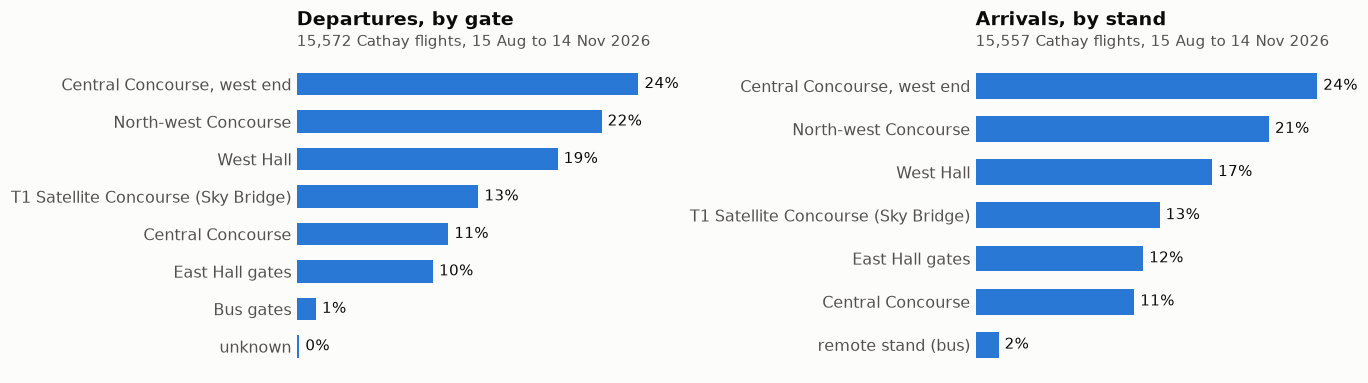

Departures with a gate we can place: 99.8%. Arrivals with a stand we can place: 100.0%.


In [8]:
hk = eda.hkia_flights()
cx = hk[(hk["carrier"] == "CX") & ~hk["cancelled"]].copy()
cx["zone"] = eda.zone_of(cx, zones)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
for ax, kind, what in zip(axes, ["dep", "arr"], ["Departures, by gate", "Arrivals, by stand"]):
    counts = cx[cx["kind"] == kind]["zone"].value_counts().sort_values()
    bars = ax.barh(counts.index, counts.values, color=charts.BLUE, height=0.6)
    ax.bar_label(bars, labels=[f"{v / counts.sum():.0%}" for v in counts.values], padding=4, fontsize=9.5, color=charts.INK)
    ax.grid(False); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
    charts.title(ax, what, f"{counts.sum():,} Cathay flights, {hk['sched_date'].min():%d %b} to {hk['sched_date'].max():%d %b %Y}")
plt.tight_layout(); plt.show()
known = cx[(cx["kind"] == "dep")]
print(f"Departures with a gate we can place: {(known['zone'] != 'unknown').mean():.1%}. "
      f"Arrivals with a stand we can place: {(cx[cx['kind'] == 'arr']['zone'] != 'unknown').mean():.1%}.")

### When does the gate become known? (REAL)

The planner only uses a gate once it has been published. Until then it plans for a far gate (the North-west
Concourse), so the walk can only get shorter when the real gate appears, never longer. The OAG status history
shows when each gate was first published:

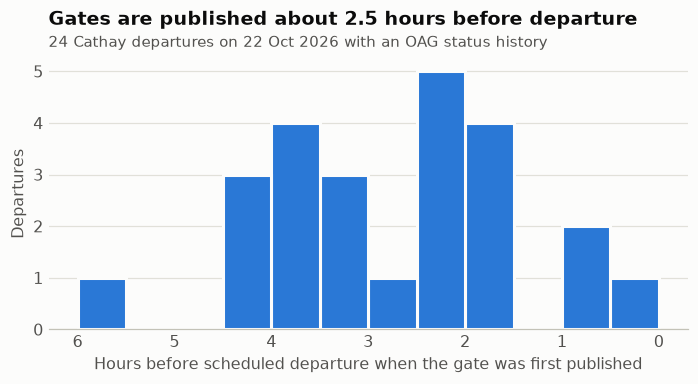

count     24.0
mean     169.0
std       79.0
min        8.0
25%      119.0
50%      149.0
75%      231.0
max      334.0


In [9]:
leads = eda.gate_publish_leads(flights).sort_values("minutes_before")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(leads["minutes_before"] / 60, bins=np.arange(0, leads["minutes_before"].max() / 60 + 0.5, 0.5),
        color=charts.BLUE, edgecolor=charts.SURFACE, linewidth=2)
ax.set_xlabel("Hours before scheduled departure when the gate was first published"); ax.set_ylabel("Departures")
ax.invert_xaxis()
charts.title(ax, f"Gates are published about {leads['minutes_before'].median() / 60:.1f} hours before departure",
             f"{len(leads)} Cathay departures on 22 Oct 2026 with an OAG status history")
plt.show()
print(leads["minutes_before"].describe().round(0).to_string())

## 4. A worked example: CX135 to Melbourne, from Central

It is 15:00 on the scenario day. CX135 leaves at 19:00, and its gate has not been published yet (it appears at
15:15). The traveller starts in Central with one checked bag, has not checked in online, is a Hong Kong resident,
and goes by car with the default margin.

In [10]:
origin_ids = {"Central": "central", "Tsim Sha Tsui": "tst", "Causeway Bay": "causeway", "Sha Tin": "shatin", "Tseung Kwan O": "tko"}
KEY = "CX135@2026-10-22T19:00"

def make_plan(origin="Central", t=at(15), flight=None, **choices):
    request = PlanRequest(origin_ids[origin], KEY, **choices)
    by_road = eda.road_lookup(roads, origin)
    road_for = (lambda when: airport_express(config)) if request.mode == "airport_express" else by_road
    return plan(request, flight or flights[KEY], t, config, zones, road_for, seed=config["seed"])

result = make_plan()
print(f"{result.flight} to {result.dest_city}, departs {result.departure:%H:%M}")
print(f"{result.deadline_kind} {result.deadline:%H:%M}  →  leave by {result.leave_by:%H:%M}")
print(f"Door to gate: usually {result.typical_total} min, up to {result.upper_total} min; the plan covers the {result.percentile}th percentile")
steps = pd.DataFrame(result.steps)[["title", "typical", "upper", "label", "note"]]
steps

CX135 to Melbourne, departs 19:00
Bag drop closes 18:00  →  leave by 16:35
Door to gate: usually 72 min, up to 91 min; the plan covers the 85th percentile


,title,typical,upper,label,note
0,To the airport,33,45,REAL,"Google traffic model, Thursday 16:00"
1,Check-in and bag drop,20,33,ASSUMED,Queue at this hour
2,Immigration and security,5,8,ASSUMED,e-Channel for residents
3,Walk to your gate,13,18,ASSUMED,950 m from check-in; planned for a far gate un...


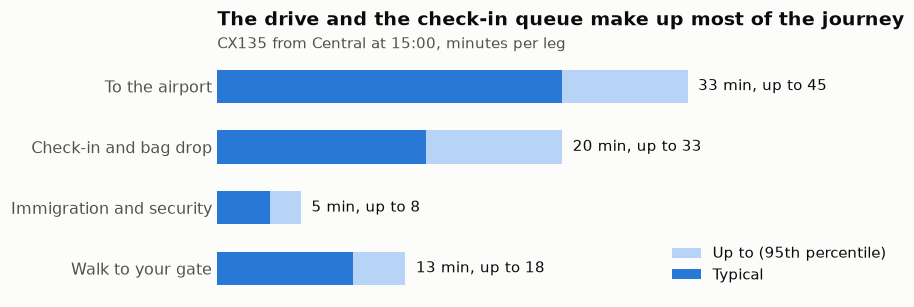

In [11]:
fig, ax = plt.subplots(figsize=(8, 2.8))
names = steps["title"][::-1]
ax.barh(names, steps["upper"][::-1], color=charts.LIGHT_BLUE, height=0.55, label="Up to (95th percentile)")
bars = ax.barh(names, steps["typical"][::-1], color=charts.BLUE, height=0.55, label="Typical")
for y, (typical, upper) in enumerate(zip(steps["typical"][::-1], steps["upper"][::-1])):
    ax.text(upper + 1, y, f"{typical} min, up to {upper}", va="center", fontsize=9.5, color=charts.INK)
ax.set_xlim(0, steps["upper"].max() * 1.45); ax.grid(False); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
ax.legend(loc="lower right")
charts.title(ax, "The drive and the check-in queue make up most of the journey", "CX135 from Central at 15:00, minutes per leg")
plt.show()

### The same flight under different choices

Each row changes one thing from the example above.

In [12]:
cases = {
    "As above (car, 1 bag, resident, balanced)": {},
    "Relaxed margin (95th percentile)": {"buffer": "relaxed"},
    "Tight margin (70th percentile)": {"buffer": "tight"},
    "Visitor (no e-Channel)": {"hk_resident": False},
    "Checked in online, no bags": {"checked_in_online": True, "bags": 0},
    "Airport Express instead of car": {"mode": "airport_express"},
}
rows = []
for name, choices in cases.items():
    p = make_plan(**choices)
    rows.append({"case": name, "deadline": f"{p.deadline_kind} {p.deadline:%H:%M}", "door_to_gate_typical": p.typical_total,
                 "door_to_gate_upper": p.upper_total, "leave_by": f"{p.leave_by:%H:%M}"})
pd.DataFrame(rows)

,case,deadline,door_to_gate_typical,door_to_gate_upper,leave_by
0,"As above (car, 1 bag, resident, balanced)",Bag drop closes 18:00,72,91,16:35
1,Relaxed margin (95th percentile),Bag drop closes 18:00,72,91,16:25
2,Tight margin (70th percentile),Bag drop closes 18:00,72,91,16:40
3,Visitor (no e-Channel),Bag drop closes 18:00,76,94,16:30
4,"Checked in online, no bags",Gate closes 18:45,55,68,17:40
5,Airport Express instead of car,Bag drop closes 18:00,83,103,16:20


In [13]:
by_origin = pd.DataFrame([{"from": origin, **{margin: f"{make_plan(origin, buffer=margin).leave_by:%H:%M}"
                                              for margin in ("relaxed", "balanced", "tight")}} for origin in order])
print("Leave-by time for CX135 (19:00), by starting point and margin")
by_origin

Leave-by time for CX135 (19:00), by starting point and margin


,from,relaxed,balanced,tight
0,Tsim Sha Tsui,16:30,16:40,16:45
1,Central,16:25,16:35,16:40
2,Sha Tin,16:30,16:35,16:40
3,Causeway Bay,16:25,16:30,16:35
4,Tseung Kwan O,16:25,16:35,16:40


### The plan moves when the airline publishes something new

The planner re-plans as the day goes on, using only what has been published by that moment:

- **The gate:** before it is published the plan assumes a far gate. Once the real gate appears, the walk is known.
- **A delay:** once the airline publishes a new departure time, every deadline moves with it.

The delay below is a what-if added to the real flight record, to show the mechanism: CX135 itself left on time.

In [14]:
before, after = make_plan(t=at(15)), make_plan(t=at(15, 20))
delayed = dict(flights[KEY])
delayed["timeline"] = flights[KEY]["timeline"] + [{"at": at(16), "state": "Scheduled", "est": at(19, 40), "on_ground": None, "gate": "49"}]
late = make_plan(t=at(16, 5), flight=delayed)
walk_step = lambda p: next(s for s in p.steps if s["key"] == "walk")
pd.DataFrame([
    {"at": "15:00", "known": "no gate yet", "walk": walk_step(before)["note"], "walk_min": walk_step(before)["typical"], "leave_by": f"{before.leave_by:%H:%M}"},
    {"at": "15:20", "known": f"gate {after.gate} published (real)", "walk": walk_step(after)["note"], "walk_min": walk_step(after)["typical"], "leave_by": f"{after.leave_by:%H:%M}"},
    {"at": "16:05", "known": "what-if: delayed to 19:40", "walk": walk_step(late)["note"], "walk_min": walk_step(late)["typical"], "leave_by": f"{late.leave_by:%H:%M}"},
])

,at,known,walk,walk_min,leave_by
0,15:00,no gate yet,950 m from check-in; planned for a far gate un...,13,16:35
1,15:20,gate 49 published (real),650 m from check-in,9,16:40
2,16:05,what-if: delayed to 19:40,650 m from check-in,9,17:15


## 5. The same terminal model protects connections

Connection Protect uses the same zones for a transfer passenger, from the aircraft door to the next gate:

```
transfer = leave the aircraft (by cabin and row) + bus (remote stands only) + transfer security + walk
```

Mei's connection in the demo: CX254 from London parks at stand N64 (North-west Concourse) and CX135 leaves from
gate 49 (West Hall). She sits in Business, row 15, and 25 Cathay flights arrive in the same half hour, so transfer
security is busy.

In [15]:
inbound, outbound = flights["CX254@2026-10-22T18:00"], flights[KEY]
inputs = TransferInputs(inbound["stand"], outbound["gate"], "J", 0.27, inbound["wave_load"])
transfer = draw_transfer(inputs, config, zones, rng_for(config["seed"], "notebook-mei"))
parts = pd.DataFrame({"leg": ["Leave the aircraft", "Transfer security", f"Walk {transfer.walk_m:.0f} m"],
                      "typical": [np.median(transfer.deplane), np.median(transfer.security), np.median(transfer.walk)],
                      "upper": [np.percentile(transfer.deplane, 90), np.percentile(transfer.security, 90), np.percentile(transfer.walk, 90)]}).round(1)
print(f"{zones.name(transfer.from_zone)} → {zones.name(transfer.to_zone)}; door to gate: "
      f"{np.percentile(transfer.total, 10):.0f} to {np.percentile(transfer.total, 90):.0f} min, typically {np.median(transfer.total):.0f}")
parts

North-west Concourse → West Hall; door to gate: 20 to 30 min, typically 26


,leg,typical,upper
0,Leave the aircraft,5.0,7.6
1,Transfer security,14.0,17.7
2,Walk 450 m,6.3,7.9


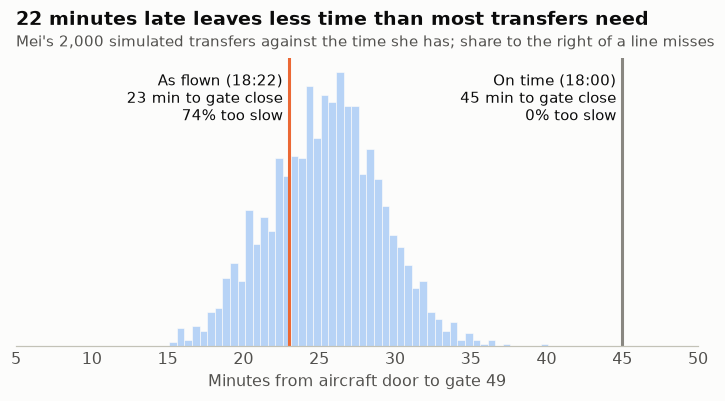

In [16]:
gate_close = outbound["sched"] - timedelta(minutes=config["gate_close_minutes"])
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(transfer.total, bins=50, color=charts.LIGHT_BLUE, edgecolor=charts.SURFACE, linewidth=0.4)
top = ax.get_ylim()[1]
for name, arrival, colour in [("On time (18:00)", inbound["sched"], charts.GREY), ("As flown (18:22)", inbound["actual"], charts.ORANGE)]:
    available = (gate_close - arrival).total_seconds() / 60
    ax.axvline(available, color=colour, linewidth=2)
    ax.text(available - 0.4, top * 0.95, f"{name}\n{available:.0f} min to gate close\n{np.mean(transfer.total > available):.0%} too slow",
            ha="right", va="top", fontsize=9.5, color=charts.INK)
ax.set_xlabel("Minutes from aircraft door to gate 49"); ax.set_yticks([]); ax.set_xlim(5, 50)
charts.title(ax, "22 minutes late leaves less time than most transfers need",
             "Mei's 2,000 simulated transfers against the time she has; share to the right of a line misses")
plt.show()

On time, every one of Mei's simulated transfers fits. With the real 22-minute delay, about three in four are too
slow. That is the view in hindsight, with the real arrival time known. In the live app the same sum is repeated
every tick with the arrival estimate published at that moment and its measured error (see the model accuracy
notebook), so her phone shows "tight" from the moment the flight leaves London late, hours before landing.

### Typical transfer walk between zones

Minutes of walking only (no security or deplaning), at 1.2 m/s:

In [17]:
arrival_zones = ["east", "central", "satellite", "mid", "west", "northwest", "midfield"]
matrix = pd.DataFrame({zones.name(b): {zones.name(a): round(zones.walk_m(a, b) / speed / 60 + zones.train_minutes(a, b))
                                        for a in arrival_zones} for b in arrival_zones})
matrix.rename_axis(index="arrive at ↓ / depart from →")

,East Hall gates,Central Concourse,T1 Satellite Concourse (Sky Bridge),"Central Concourse, west end",West Hall,North-west Concourse,Midfield Concourse
arrive at ↓ / depart from →,,,,,,,
East Hall gates,2,6,12,9,12,17,18
Central Concourse,6,2,9,6,9,13,15
T1 Satellite Concourse (Sky Bridge),12,9,2,12,16,20,22
"Central Concourse, west end",9,6,12,2,6,10,12
West Hall,12,9,16,6,2,6,8
North-west Concourse,17,13,20,10,6,2,12
Midfield Concourse,18,15,22,12,8,12,2


## Limits, stated plainly

- **Walking distances are assumed.** They come from our reading of the public terminal map. The structure (real
  stand and gate numbers mapped to zones) is ready for measured times.
- **Queues are assumed.** Check-in, immigration and security times are documented assumptions, not measurements.
  The visitor immigration figure follows the Immigration Department's pledge (95% within 15 minutes).
- **Road times are Google's model for a typical Thursday,** not a recording of the scenario day.
- **Five starting points.** The planner uses area names, not a traveller's exact address.

**What Cathay's own data would replace:** measured queue times by hour, real walking times between gates, and
the traveller's actual check-in and bag status. The engine and the app would not change.